# Rossmann — Ventas, promociones y contexto comercial

## 1. Objetivo, población y límites

**Pregunta principal:** ¿cómo se relacionan las promociones, el calendario y las
características de las tiendas con el desempeño de ventas? **Pregunta secundaria:**
¿qué caracteriza las observaciones con mayor nivel de ventas?

Se aplican AGENTS.md, requirements.md y las decisiones finales aprobadas de la
Fase 1. Revisión: **17 de octubre de 2026**. La única fuente de observaciones es
`data/processed/rossmann_clean.csv`. No se repite la auditoría ni se cambia el clean.

La unidad de análisis es **tienda–día**, no el total diario de la cadena. La
población principal son las filas **Open = 1**. Se conservan deliberadamente las
**54 filas abiertas con Sales = 0**, incluidas las 2 con clientes positivos.
Los cierres solo se incorporan cuando interesa el volumen total registrado o la
fracción de apertura; no se mezclan con el rendimiento de los días abiertos.

Se conservan outliers, los faltantes estructurales de Promo2 y los desconocidos de
competencia, incluido el año 1900. Las 33.121 combinaciones históricas ausentes
siguen ausentes; no se suponen ventas o apertura cero en días sin observación.

Todos los contrastes son **asociaciones descriptivas**, sin estimar efectos
causales. No hay asignación aleatoria; tiendas, días, meses y exposición pueden
ser distintos entre grupos. No se crean un target, particiones, imputaciones,
encoding, scaling, modelos ni un dataset de ML. Las variables auxiliares y las
ocho figuras existen únicamente en este notebook.

In [1]:
from pathlib import Path
from datetime import date
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 40)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10})
COLORS = ['#52758b', '#d78335']
DOW = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
SALES_UNIT = 'Sales (unidades del CSV)'

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data' / 'processed' / 'rossmann_clean.csv').is_file())
CLEAN_PATH = ROOT / 'data' / 'processed' / 'rossmann_clean.csv'

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

clean_sha_before = file_sha256(CLEAN_PATH)
assert clean_sha_before == '02dbaaa1491f9380c148ddc01e8d4eb808ae98da1790cef4576a68bee681d28a', 'Revisar cambio respecto del clean aprobado'
protected_paths = [p for folder in ['data', 'notebooks'] for p in (ROOT / folder).rglob('*')
                   if p.is_file() and p != ROOT / 'notebooks' / '02_eda_promotions.ipynb']
protected_paths += [ROOT / n for n in ['AGENTS.md', 'requirements.md', 'README.md']]
protected_hashes = {str(p.relative_to(ROOT)): file_sha256(p) for p in protected_paths}

clean = pd.read_csv(CLEAN_PATH, low_memory=False, parse_dates=['Date'],
                    dtype={c: 'string' for c in ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']})
assert pd.api.types.is_datetime64_any_dtype(clean['Date'])
assert clean.shape == (1_017_209, 18)
clean_frame_before = hashlib.sha256(pd.util.hash_pandas_object(clean, index=True).values.tobytes()).hexdigest()
clean_schema_before = (tuple(clean.columns), tuple(map(str, clean.dtypes)))

# Solo eda recibe variables auxiliares; clean permanece intacto en memoria y disco.
eda = clean.copy()
eda['Month'] = eda['Date'].dt.to_period('M')
eda['SalesPerCustomer'] = eda['Sales'].div(eda['Customers'].where(eda['Customers'].gt(0)))
open_days = eda.loc[eda['Open'].eq(1)].copy()
assert (open_days['Sales'].eq(0)).sum() == 54
assert (open_days['Sales'].eq(0) & open_days['Customers'].gt(0)).sum() == 2
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
print('SHA-256 del clean:', clean_sha_before)
display(pd.DataFrame([
    {'poblacion': 'Completa: todas las observaciones disponibles', 'tienda_dias': len(clean), 'tiendas': clean['Store'].nunique()},
    {'poblacion': 'Principal: días abiertos, incluidos 54 con ventas cero', 'tienda_dias': len(open_days), 'tiendas': open_days['Store'].nunique()}
]))

def commercial_summary(group):
    # SalesPerCustomer es NA exclusivamente cuando Customers=0; no se imputa.
    return pd.Series({
        'tienda_dias': len(group), 'tiendas': group['Store'].nunique(),
        'Sales_media': group['Sales'].mean(), 'Sales_mediana': group['Sales'].median(),
        'Customers_media': group['Customers'].mean(), 'Customers_mediana': group['Customers'].median(),
        'Sales_per_customer_media': group['SalesPerCustomer'].mean(),
        'Sales_per_customer_ponderada': group.loc[group['Customers'].gt(0), 'Sales'].sum() / group.loc[group['Customers'].gt(0), 'Customers'].sum(),
        'filas_ratio_valido': group['Customers'].gt(0).sum()
    })

def summaries(frame, keys):
    return frame.groupby(keys, observed=True, dropna=False).apply(commercial_summary, include_groups=False)

figures_created = []
def finish_figure(fig, number):
    fig.tight_layout()
    figures_created.append(number)
    plt.show()
    plt.close(fig)

Python 3.13.7 | pandas 3.0.2 | numpy 2.4.4
SHA-256 del clean: 02dbaaa1491f9380c148ddc01e8d4eb808ae98da1790cef4576a68bee681d28a


,poblacion,tienda_dias,tiendas
0,Completa: todas las observaciones disponibles,1017209,1115
1,"Principal: días abiertos, incluidos 54 con ventas cero",844392,1115


**Poblaciones verificadas.** 844.392 de 1.017.209 registros son días abiertos
(83,01 %). El filtro de apertura es una selección analítica, no una
limpieza. Las divisiones por clientes se restringen a Customers > 0: los
52 días abiertos sin clientes siguen en el resto de métricas,
pero no tienen un cociente definido. Los 2 casos con clientes positivos y ventas
cero sí aportan un cociente cero.

## 2. KPIs generales y definiciones

Sea A el conjunto de tienda–días abiertos, P los de Promo = 1 y N los de Promo = 0.

| KPI | Fórmula y denominador |
|---|---|
| Ventas totales registradas | Suma de Sales en todo el clean; se muestra también la suma sobre A. |
| Ventas medias por día abierto | Suma de Sales en A / número de tienda–días en A. |
| Mediana de ventas | Mediana de Sales en A, incluidos los ceros conservados. |
| Clientes medios | Suma de Customers en A / número de tienda–días en A. |
| Ventas por cliente: media de cocientes | Media de Sales / Customers sobre A y Customers > 0; cada tienda–día válido pesa igual. |
| Ventas por cliente: cociente agregado | Suma de Sales / suma de Customers sobre ese mismo subconjunto; pondera por clientes. |
| Porcentaje de abiertos con Promo | Número de registros A con Promo = 1 / número de registros A × 100. |
| Media con/sin Promo | Media de Sales en A∩P y A∩N, respectivamente. |
| Uplift observado de Promo | (Media en A∩P / media en A∩N − 1) × 100. |

Las unidades monetarias se mantienen como **unidades de Sales del CSV**, sin
asumir una moneda o ajuste por precios. Customers representa el conteo informado;
Sales / Customers es ventas por cliente, no necesariamente un ticket de caja.

In [2]:
population_kpis = pd.DataFrame({
    'dataset_completo': commercial_summary(eda),
    'solo_dias_abiertos': commercial_summary(open_days)
})
population_kpis.loc['Sales_total'] = [eda['Sales'].sum(), open_days['Sales'].sum()]
display(population_kpis)
promo_summary = summaries(open_days, 'Promo')
promo_uplift = (promo_summary.loc[1, 'Sales_media'] / promo_summary.loc[0, 'Sales_media'] - 1) * 100
promo_share = open_days['Promo'].eq(1).mean() * 100
display(promo_summary)
display(pd.DataFrame({'KPI': ['Abiertos con Promo (%)', 'Uplift global observado (%)'],
                      'valor': [promo_share, promo_uplift]}))

,dataset_completo,solo_dias_abiertos
tienda_dias,1.017209e+06,8.443920e+05
tiendas,1.115000e+03,1.115000e+03
Sales_media,5.773819e+03,6.955514e+03
Sales_mediana,5.744000e+03,6.369000e+03
Customers_media,6.331459e+02,7.627284e+02
Customers_mediana,6.090000e+02,6.760000e+02
Sales_per_customer_media,9.493619e+00,9.493619e+00
Sales_per_customer_ponderada,9.119254e+00,9.119254e+00
filas_ratio_valido,8.443400e+05,8.443400e+05
Sales_total,5.873181e+09,5.873181e+09


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Promo,,,,,,,,,
0,467496.0,1115.0,5929.407603,5459.0,696.856886,610.0,8.941128,8.508788,467463.0
1,376896.0,1115.0,8228.281239,7649.0,844.434401,757.0,10.178907,9.744133,376877.0


,KPI,valor
0,Abiertos con Promo (%),44.635193
1,Uplift global observado (%),38.770714


**EVIDENCIA.** Se registran 5.873.180.623 unidades de Sales. En días abiertos la
media es 6.955,51, la mediana 6.369,00 y los clientes medios
762,73. La media de ventas por cliente es 9,49, frente a
9,12 en el cociente agregado. 44,64 % de los días abiertos
tienen Promo.

**INTERPRETACIÓN.** El volumen y el rendimiento por exposición responden preguntas
distintas. La media de todos los registros incluye cierres y no es el KPI principal
de desempeño. La diferencia entre los dos cocientes por cliente proviene de su
ponderación; no deben presentarse como si fueran el mismo indicador.

## 3. Evolución temporal: volumen frente a exposición

**Pregunta:** ¿los cambios mensuales de volumen se acompañan de cambios en ventas
por día abierto o pueden relacionarse con cobertura y cantidad de días?

Se muestra el total registrado y la media por tienda–día abierto. Como contraste
de composición, se agrega una **cohorte fija de tiendas con todos los días
observados** del histórico, sin completar huecos. Esta cohorte es solo un control
descriptivo; no sustituye la población principal ni balancea aperturas o promociones.

,Sales_total,filas,tiendas,fechas_observadas,Sales_media_abiertas,abiertos,Promo_pct,Sales_media_cohorte_fija,dias_calendario_mes,cobertura_tienda_dia_pct
Month,,,,,,,,,,
2013-01,180132207,34564,1115,31,6239.641380,28869,38.321383,6299.049729,31,99.997107
2013-02,171534275,31220,1115,28,6428.597796,26683,41.599520,6508.534294,28,100.000000
2013-03,201180369,34565,1115,31,7212.834110,27892,55.779435,7303.536492,31,100.000000
2013-04,183431432,33450,1115,30,6579.319656,27880,47.736729,6649.044154,30,100.000000
2013-05,185411063,34565,1115,31,7076.217960,26202,48.381803,7135.796668,31,100.000000
2013-06,180702351,33450,1115,30,6467.051428,27942,39.778828,6521.349987,30,100.000000
2013-07,208843882,34565,1115,31,6923.154611,30166,47.928131,6975.389587,31,100.000000
2013-08,198042727,34565,1115,31,6595.927627,30025,43.986678,6631.106509,31,100.000000
2013-09,178053963,33450,1115,30,6363.388121,27981,39.784139,6407.444246,30,100.000000


Tiendas de la cohorte fija: 934


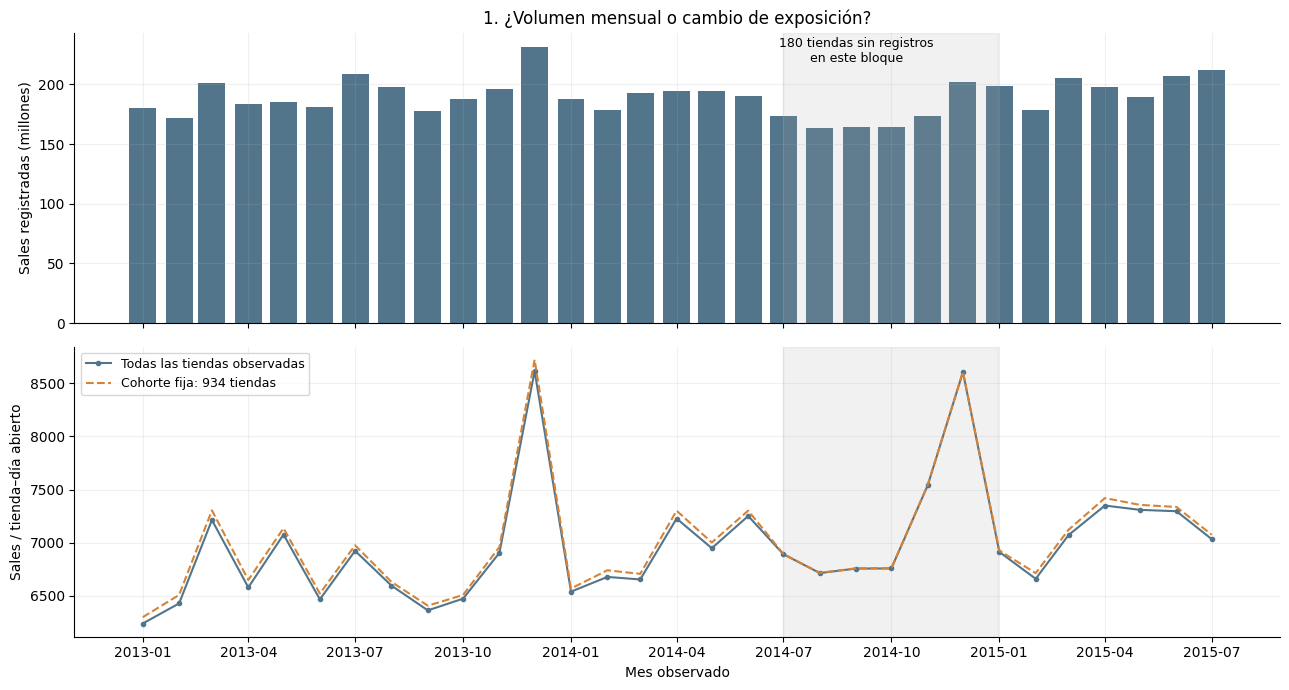

In [3]:
monthly = eda.groupby('Month', observed=True).agg(
    Sales_total=('Sales', 'sum'), filas=('Store', 'size'), tiendas=('Store', 'nunique'),
    fechas_observadas=('Date', 'nunique'))
monthly_open = open_days.groupby('Month', observed=True).agg(
    Sales_media_abiertas=('Sales', 'mean'), abiertos=('Store', 'size'),
    Promo_pct=('Promo', lambda s: s.mean() * 100))
monthly = monthly.join(monthly_open)
coverage_per_store = eda.groupby('Store')['Date'].nunique()
fixed_stores = coverage_per_store.index[coverage_per_store.eq(eda['Date'].nunique())]
monthly['Sales_media_cohorte_fija'] = (
    open_days.loc[open_days['Store'].isin(fixed_stores)]
    .groupby('Month', observed=True)['Sales'].mean())
monthly['dias_calendario_mes'] = monthly.index.days_in_month
monthly['cobertura_tienda_dia_pct'] = monthly['filas'] / (clean['Store'].nunique() * monthly['dias_calendario_mes']) * 100
display(monthly)
print('Tiendas de la cohorte fija:', len(fixed_stores))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
dates = monthly.index.to_timestamp()
axes[0].bar(dates, monthly['Sales_total'] / 1e6, width=23, color=COLORS[0])
axes[0].set(title='1. ¿Volumen mensual o cambio de exposición?', ylabel='Sales registradas (millones)')
axes[1].plot(dates, monthly['Sales_media_abiertas'], label='Todas las tiendas observadas', color=COLORS[0], marker='o', markersize=3)
axes[1].plot(dates, monthly['Sales_media_cohorte_fija'], label=f'Cohorte fija: {len(fixed_stores)} tiendas', color=COLORS[1], linestyle='--')
axes[1].set(ylabel='Sales / tienda–día abierto', xlabel='Mes observado')
axes[1].legend(loc='upper left', fontsize=9)
for ax in axes:
    ax.axvspan(pd.Timestamp('2014-07-01'), pd.Timestamp('2014-12-31'), color='#a9a9a9', alpha=.16)
axes[0].text(pd.Timestamp('2014-09-01'), axes[0].get_ylim()[1] * .9,
             '180 tiendas sin registros\nen este bloque', ha='center', fontsize=9)
finish_figure(fig, 1)

**EVIDENCIA.** El mes con mayor media por día abierto es 2013-12:
8.613,46. En julio–diciembre de 2014 se observan 935 tiendas por mes,
frente a 1.115 en la mayoría de los restantes; la cohorte fija contiene
934 tiendas. En diciembre de 2013 y 2014 las medias son 8.613,46 y 8.603,81.

**INTERPRETACIÓN.** Los cierres, la duración del mes y la cobertura afectan el total.
La referencia de cohorte fija permite comprobar si un patrón también aparece sin
cambiar esas tiendas, pero no controla calendario ni apertura. Los dos diciembres
son compatibles con un pico comercial recurrente; dos años completos y un 2015
hasta julio no bastan para aislar estacionalidad, tendencia o sus causas. No se
interpreta la caída de volumen del bloque incompleto como deterioro comercial.

## 4. Promo: comparación principal sobre días abiertos

**Pregunta:** ¿cómo difieren las ventas, los clientes y el valor por cliente con
Promo y sin Promo, manteniendo constante que la tienda está abierta?

,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Promo,,,,,,,,,
0,467496.0,1115.0,5929.407603,5459.0,696.856886,610.0,8.941128,8.508788,467463.0
1,376896.0,1115.0,8228.281239,7649.0,844.434401,757.0,10.178907,9.744133,376877.0


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Promo,,,,,,,,,
0,319845.0,1115.0,5928.200125,5465.0,705.011887,623.0,8.825341,8.408653,319818.0
1,376896.0,1115.0,8228.281239,7649.0,844.434401,757.0,10.178907,9.744133,376877.0


Uplift observado solo lunes–viernes (%): 38.79897887730155


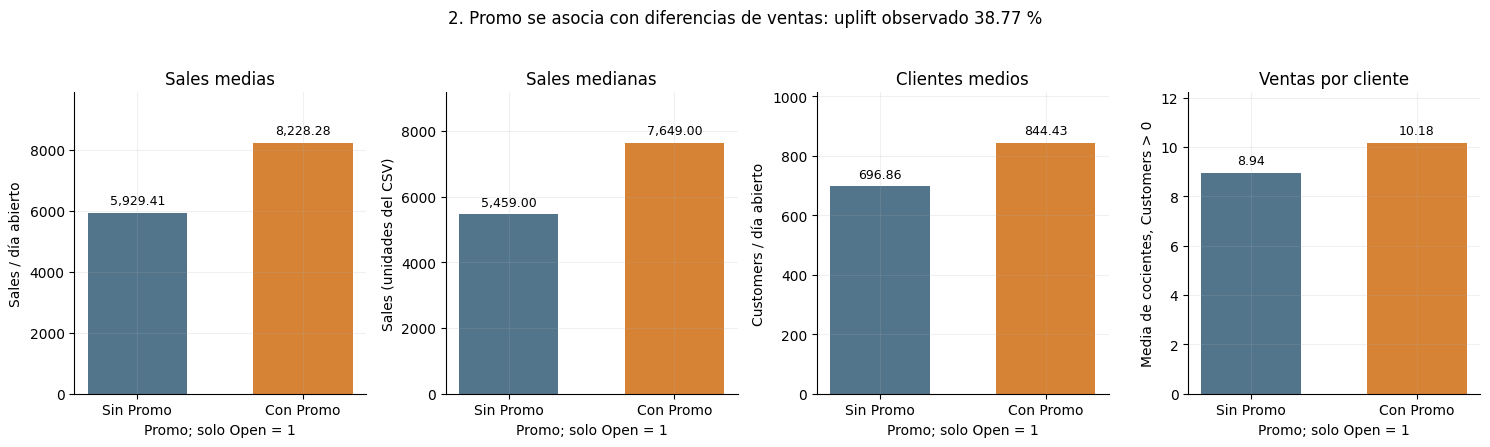

In [4]:
display(promo_summary)
weekday_promo = summaries(open_days.loc[open_days['DayOfWeek'].le(5)], 'Promo')
weekday_uplift = (weekday_promo.loc[1, 'Sales_media'] / weekday_promo.loc[0, 'Sales_media'] - 1) * 100
display(weekday_promo)
print('Uplift observado solo lunes–viernes (%):', weekday_uplift)

fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
metrics = [('Sales_media', 'Sales medias', 'Sales / día abierto'),
           ('Sales_mediana', 'Sales medianas', SALES_UNIT),
           ('Customers_media', 'Clientes medios', 'Customers / día abierto'),
           ('Sales_per_customer_media', 'Ventas por cliente', 'Media de cocientes, Customers > 0')]
for ax, (col, title, label) in zip(axes, metrics):
    values = promo_summary.loc[[0, 1], col]
    bars = ax.bar(['Sin Promo', 'Con Promo'], values, color=COLORS, width=.6)
    ax.bar_label(bars, labels=[f'{v:,.2f}' for v in values], padding=4, fontsize=9)
    ax.set(title=title, ylabel=label, xlabel='Promo; solo Open = 1', ylim=(0, values.max() * 1.2))
fig.suptitle(f'2. Promo se asocia con diferencias de ventas: uplift observado {promo_uplift:.2f} %', y=1.03)
finish_figure(fig, 2)

**EVIDENCIA.** Con Promo, la venta media es 8.228,28 y la mediana
7.649,00, frente a 5.929,41 y 5.459,00 sin Promo.
El uplift global observado es **38,77 %**. Los clientes medios son
844,43 frente a 696,86, y la media de ventas por
cliente 10,18 frente a 8,94. Al restringir ambos grupos
a lunes–viernes, el contraste de medias es 38,80 %.

**INTERPRETACIÓN.** La asociación no se limita a una diferencia de ventas: también
intervienen tráfico y valor por cliente. Promo no aparece en fines de semana, por
lo que el uplift global mezcla calendarios distintos. Sin embargo, al restringir
a lunes–viernes el contraste prácticamente no cambia: la asociación observada no
parece explicarse solo por excluir fines de semana. Esto no resuelve selección de
tiendas, fechas o intensidad promocional. Ninguno de estos contrastes mide ventas
incrementales causadas por Promo.

## 5. Promo por tienda: alcance y heterogeneidad

**Pregunta:** ¿la asociación se concentra en algunas tiendas o se observa en una
parte amplia de la red? Para cada Store se calcula el mismo cociente de medias,
usando exclusivamente sus días abiertos. Se exige soporte en ambos estados y media
sin Promo positiva. La mediana de uplifts da **igual peso a cada tienda**; difiere
del contraste global, ponderado implícitamente por observaciones y volumen.

,uplift_pct,n_sin_Promo,n_con_Promo
count,1115.000000,1115.000000,1115.000000
mean,41.431123,419.278924,338.023318
std,18.101290,37.945963,28.506061
min,-6.946978,329.000000,263.000000
10%,19.970888,348.000000,274.000000
25%,29.360508,428.000000,348.000000
50%,40.561467,429.000000,350.000000
75%,51.843882,431.000000,352.500000
90%,64.045795,431.000000,353.000000
max,144.928396,582.000000,360.000000


Tiendas elegibles/excluidas por falta de soporte o denominador: 1115 0
Uplift positivo, porcentaje de tiendas: 99.91031390134529
Extremos inferiores:


,Sales_sin_Promo,Sales_con_Promo,n_sin_Promo,n_con_Promo,uplift_pct,StoreType,Assortment
Store,,,,,,,
274,4182.435540,3891.882682,574,358,-6.946978,b,b
262,20549.637457,20991.536111,582,360,2.150396,b,a
948,6865.652705,7051.535211,573,355,2.707427,b,b
827,12587.897674,12995.518414,430,353,3.238196,a,c
553,6928.909091,7173.818966,429,348,3.534609,c,a


Extremos superiores:


,Sales_sin_Promo,Sales_con_Promo,n_sin_Promo,n_con_Promo,uplift_pct,StoreType,Assortment
Store,,,,,,,
198,1753.461538,4294.725212,429,353,144.928396,a,a
607,2551.573427,5542.971671,429,353,117.237396,a,a
543,1868.129930,3926.065714,431,350,110.160206,c,a
575,3614.405172,7586.112727,348,275,109.885510,a,a
693,4577.874710,9107.817143,431,350,98.952958,d,a


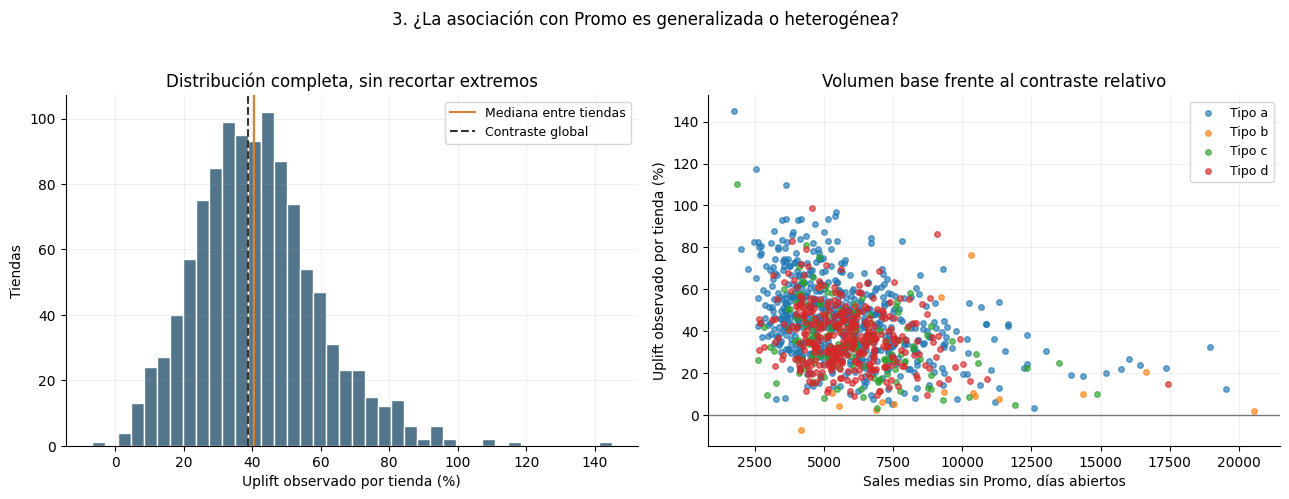

In [5]:
store_promo_means = open_days.groupby(['Store', 'Promo'], observed=True)['Sales'].mean().unstack('Promo')
store_promo_n = open_days.groupby(['Store', 'Promo'], observed=True).size().unstack('Promo')
valid_store_promo = store_promo_means[[0, 1]].notna().all(axis=1) & store_promo_means[0].gt(0)
store_uplift = pd.DataFrame({
    'Sales_sin_Promo': store_promo_means.loc[valid_store_promo, 0],
    'Sales_con_Promo': store_promo_means.loc[valid_store_promo, 1],
    'n_sin_Promo': store_promo_n.loc[valid_store_promo, 0],
    'n_con_Promo': store_promo_n.loc[valid_store_promo, 1]})
store_uplift['uplift_pct'] = (store_uplift['Sales_con_Promo'] / store_uplift['Sales_sin_Promo'] - 1) * 100
store_metadata = clean.groupby('Store', observed=True)[['StoreType', 'Assortment']].first()
store_uplift = store_uplift.join(store_metadata, validate='one_to_one')
display(store_uplift[['uplift_pct', 'n_sin_Promo', 'n_con_Promo']].describe(percentiles=[.1, .25, .5, .75, .9]))
print('Tiendas elegibles/excluidas por falta de soporte o denominador:', len(store_uplift), clean['Store'].nunique() - len(store_uplift))
print('Uplift positivo, porcentaje de tiendas:', store_uplift['uplift_pct'].gt(0).mean() * 100)
print('Extremos inferiores:')
display(store_uplift.nsmallest(5, 'uplift_pct'))
print('Extremos superiores:')
display(store_uplift.nlargest(5, 'uplift_pct'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(store_uplift['uplift_pct'], bins=40, color=COLORS[0], edgecolor='white')
axes[0].axvline(store_uplift['uplift_pct'].median(), color=COLORS[1], label='Mediana entre tiendas')
axes[0].axvline(promo_uplift, color='#333333', linestyle='--', label='Contraste global')
axes[0].set(title='Distribución completa, sin recortar extremos', xlabel='Uplift observado por tienda (%)', ylabel='Tiendas')
axes[0].legend(fontsize=9)
for st, group in store_uplift.groupby('StoreType', observed=True):
    axes[1].scatter(group['Sales_sin_Promo'], group['uplift_pct'], s=16, alpha=.65, label=f'Tipo {st}')
axes[1].axhline(0, color='#777777', linewidth=1)
axes[1].set(title='Volumen base frente al contraste relativo', xlabel='Sales medias sin Promo, días abiertos', ylabel='Uplift observado por tienda (%)')
axes[1].legend(fontsize=9)
fig.suptitle('3. ¿La asociación con Promo es generalizada o heterogénea?', y=1.03)
finish_figure(fig, 3)

**EVIDENCIA.** 1.115 tiendas tienen ambos estados y denominador válido.
La mediana del uplift es **40,56 %**, el intervalo intercuartílico
29,36–51,84 %, y 99,91 % presenta un
contraste positivo. Los extremos van de -6,95 a 144,93 %;
las tablas identifican sus tiendas y el soporte de cada grupo.

**INTERPRETACIÓN.** El contraste positivo en **1.114 de 1.115 tiendas** muestra un
patrón extendido, aunque con magnitudes heterogéneas. Store 274 es la única con
contraste negativo (−6,95 %); Store 198 alcanza 144,93 % con una base de 1.753,46
sin Promo. El cociente puede crecer
cuando el nivel base es bajo, y el mix de calendario sigue siendo distinto dentro
de cada tienda. Los extremos no se consideran errores. No se promedian estos
porcentajes como si fueran el retorno económico de una campaña.

## 6. StoreType y Assortment

**Pregunta:** ¿difieren el nivel base y la asociación con Promo según formato y
surtido? Los códigos originales se conservan. Se muestran medias, medianas,
clientes y cantidad de tiendas para contextualizar grupos pequeños.

Desempeño en días abiertos por StoreType


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
StoreType,,,,,,,,,
a,457077.0,602.0,6925.167661,6285.0,795.361469,720.0,8.846277,8.706944,457043.0
b,15563.0,17.0,10231.407505,9130.0,2021.822335,1839.0,5.133097,5.060488,15561.0
c,112978.0,148.0,6932.512755,6407.0,815.465887,756.0,8.626227,8.501291,112968.0
d,258774.0,348.0,6822.141881,6395.0,606.339876,577.0,11.277862,11.251350,258768.0


tienda_dias  tiendas   Sales_media  Sales_mediana  Customers_media  Customers_mediana  Sales_per_customer_media  Sales_per_customer_ponderada  filas_ratio_valido
StoreType Promo                                                                                                                                                                   
a         0         252556.0    602.0   5808.500091         5313.0       713.808454              641.0                  8.358145                      8.137337            252532.0
          1         204521.0    602.0   8304.102317         7646.0       896.068502              814.0                  9.449026                      9.267263            204511.0
b         0           9623.0     17.0   9566.861686         8516.0      1941.804531             1753.0                  5.009602                      4.926789              9622.0
          1           5940.0     17.0  11307.994108        10202.5      2151.453872             2011.0                  5.333175                      5.255978              5939.0
c         0          62240.0    148.0   6028.063255         5523.0       758.711536              698.0                  8.100421                      7.945132             62235.0
          1          50738.0    148.0   8041.995526         7572.0       885.086109              833.0                  9.271242                      9.086117             50733.0
d         0         143077.0    348.0   5855.268289         5551.0       556.294918              531.0                 10.600216                     10.525475            143074.0
          1         115697.0    348.0   8017.828656         7626.0       668.228104              641.0                 12.115879                     11.998640            115694.0

Promo,0,1,uplift_observado_pct
StoreType,,,
a,5808.500091,8304.102317,42.964658
b,9566.861686,11307.994108,18.199619
c,6028.063255,8041.995526,33.409276
d,5855.268289,8017.828656,36.933583


Mediana de contrastes por tienda (peso igual), StoreType


...

,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Assortment,,,,,,,,,
a,444909.0,593.0,6621.017039,6082.0,747.943822,673.0,9.130786,8.852292,444876.0
b,8212.0,9.0,8639.346322,8081.0,2066.795543,1894.0,4.163219,4.180068,8210.0
c,391271.0,513.0,7300.526339,6675.0,752.169959,672.0,10.018030,9.705953,391254.0


tienda_dias  tiendas  Sales_media  Sales_mediana  Customers_media  Customers_mediana  Sales_per_customer_media  Sales_per_customer_ponderada  filas_ratio_valido
Assortment Promo                                                                                                                                                                  
a          0         245989.0    593.0  5559.715325         5133.0       674.615215              600.0                  8.583666                      8.241313            245967.0
           1         198920.0    593.0  7933.446898         7393.0       838.623648              760.0                  9.807345                      9.460080            198909.0
b          0           5078.0      9.0  8398.199882         7850.0      2011.105356             1838.0                  4.168919                      4.175912              5077.0
           1           3134.0      9.0  9030.074346         8521.5      2157.029994             1987.5                  4.153980                      4.186346              3133.0
c          0         216429.0    513.0  6291.668238         5786.0       691.300574              614.0                  9.459346                      9.101205            216419.0
           1         174842.0    513.0  8549.346130         7935.0       827.517416              748.0                 10.709597                     10.331319            174835.0

Promo,0,1,uplift_observado_pct
Assortment,,,
a,5559.715325,7933.446898,42.695200
b,8398.199882,9030.074346,7.523927
c,6291.668238,8549.346130,35.883613


Mediana de contrastes por tienda (peso igual), Assortment


,size,median,min,max
Assortment,,,,
a,593,44.551813,2.150396,144.928396
b,9,7.663852,-6.946978,10.977031
c,513,36.265844,3.238196,86.623612


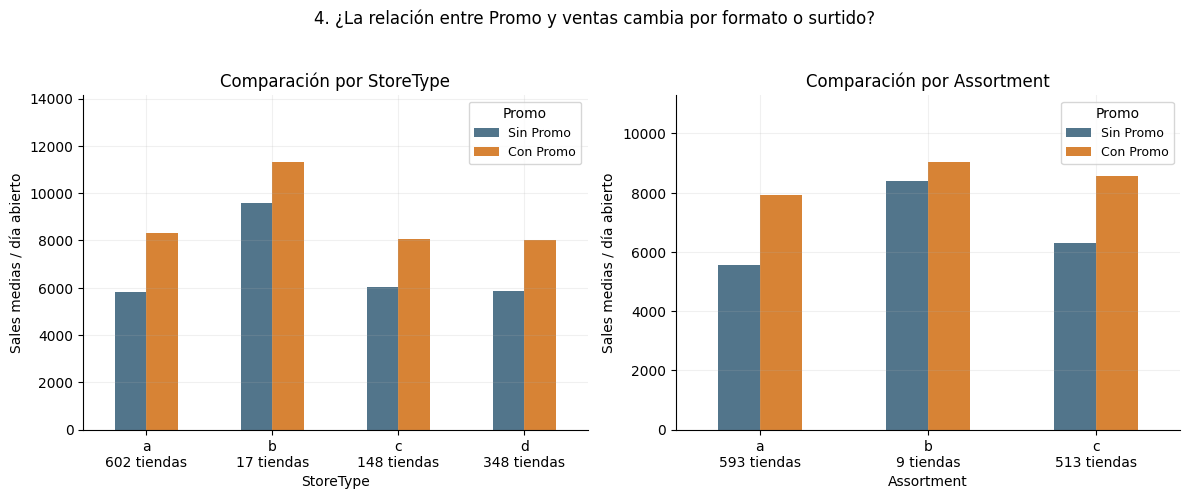

In [6]:
attribute_summary = {}
attribute_promo = {}
for attr in ['StoreType', 'Assortment']:
    print('Desempeño en días abiertos por', attr)
    attribute_summary[attr] = summaries(open_days, attr)
    display(attribute_summary[attr])
    grouped = summaries(open_days, [attr, 'Promo'])
    means = grouped['Sales_media'].unstack('Promo')
    means['uplift_observado_pct'] = (means[1] / means[0] - 1) * 100
    attribute_promo[attr] = means
    display(grouped)
    display(means)
    print('Mediana de contrastes por tienda (peso igual),', attr)
    display(store_uplift.groupby(attr, observed=True)['uplift_pct'].agg(['size', 'median', 'min', 'max']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, attr in zip(axes, ['StoreType', 'Assortment']):
    attribute_promo[attr][[0, 1]].rename(columns={0: 'Sin Promo', 1: 'Con Promo'}).plot.bar(ax=ax, color=COLORS, rot=0)
    labels = [f'{k}\n{int(attribute_summary[attr].loc[k, "tiendas"])} tiendas' for k in attribute_promo[attr].index]
    ax.set_xticklabels(labels)
    ax.set(title=f'Comparación por {attr}', ylabel='Sales medias / día abierto', xlabel=attr)
    ax.set_ylim(0, attribute_promo[attr][[0, 1]].to_numpy().max() * 1.25)
    ax.legend(title='Promo', fontsize=9)
fig.suptitle('4. ¿La relación entre Promo y ventas cambia por formato o surtido?', y=1.03)
finish_figure(fig, 4)

**EVIDENCIA.** StoreType b registra 10.231,41 Sales medias y un contraste
Promo de 18,20 %, frente a 42,96 % en tipo a. Assortment b
tiene solo **9 tiendas**; StoreType b, **17**. Los contrastes por tipo van de
18,20 a 42,96 % y por surtido de 7,52 a
42,70 %.

Assortment c tiene una media de 7.300,53 frente a 6.621,02 en a,
con clientes medios muy parecidos (752,17 frente a
747,94). La media de ventas por cliente es 10,02 en c
y 9,13 en a.

**INTERPRETACIÓN.** Conviene segmentar el análisis y no asignar el contraste
global a todos los formatos. Medias, medianas y clientes ayudan a separar tamaño
de tienda y valor relativo. Los grupos pequeños y la composición de tiendas pueden
influir: una diferencia agregada por formato no demuestra que cambiar formato,
surtido o promoción produzca ese resultado. La tabla de medianas por tienda aporta
una comparación complementaria con igual peso, todavía descriptiva.

## 7. Calendario: apertura frente a desempeño condicionado

**Pregunta:** ¿el calendario se relaciona con abrir, con vender cuando se abre, o
con ambas cosas? La «probabilidad de apertura» es la **fracción empírica de Open = 1
entre filas observadas de cada categoría**. No incorpora días ausentes ni es un
pronóstico de apertura.

Calendario: DayOfWeek


,observados,apertura_pct,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
DayOfWeek,,,,,,,,,,,
1,144730,95.045948,137560.0,1115.0,8216.073074,7539.0,855.444984,769.0,9.896977,9.604444,137557.0
2,145664,98.830871,143961.0,1115.0,7088.113656,6502.0,769.986753,684.0,9.594422,9.205501,143956.0
3,145665,97.440016,141936.0,1115.0,6728.122978,6210.0,740.598876,658.0,9.496812,9.084706,141922.0
4,145845,92.319929,134644.0,1115.0,6767.310159,6246.0,755.569784,673.0,9.358152,8.956565,134627.0
5,145845,95.059824,138640.0,1115.0,7072.677012,6580.0,781.771639,698.0,9.438295,9.046986,138633.0
6,144730,99.535687,144058.0,1115.0,5874.840238,5425.0,660.177526,573.0,9.260104,8.898879,144052.0
7,144730,2.482554,3593.0,33.0,8224.723908,6876.0,1441.532424,1262.0,6.458913,5.705542,3593.0


Calendario: StateHoliday


,observados,apertura_pct,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
StateHoliday,,,,,,,,,,,
0,986159,85.532049,843482.0,1115.0,6953.515034,6368.0,762.076719,675.0,9.496046,9.124429,843430.0
a,20260,3.425469,694.0,156.0,8487.471182,7556.0,1279.172911,887.0,7.537288,6.635124,694.0
b,6690,2.167414,145.0,32.0,9887.889655,8423.0,1686.889655,1554.0,6.321028,5.861610,145.0
c,4100,1.731707,71.0,20.0,9743.746479,8397.0,1569.225352,1394.0,6.269964,6.209272,71.0


Calendario: SchoolHoliday


...

Soporte por día y Promo; los ceros son conteos, no imputaciones:


Promo,0,1
DayOfWeek,,
1,60317,77243
2,66843,77118
3,65679,76257
4,60521,74123
5,66485,72155
6,144058,0
7,3593,0


Promo,0,1
DayOfWeek,,
1,6222.521495,9772.784369
2,5716.241087,8277.201522
3,5617.044778,7685.077816
4,5749.837412,7598.070761
5,6344.030127,7744.066219
6,5874.840238,NaN
7,8224.723908,NaN


Composición de los días abiertos en domingo:


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido,participacion_dias_dominicales_pct
StoreType,,,,,,,,,,
a,1100.0,13.0,2912.109091,2582.0,400.706364,330.0,7.709035,7.267439,1100.0,30.615085
b,2216.0,17.0,11449.909296,9986.5,2091.121841,1845.0,5.489788,5.475486,2216.0,61.675480
d,277.0,3.0,3520.267148,3264.0,378.061372,373.0,9.247526,9.311364,277.0,7.709435


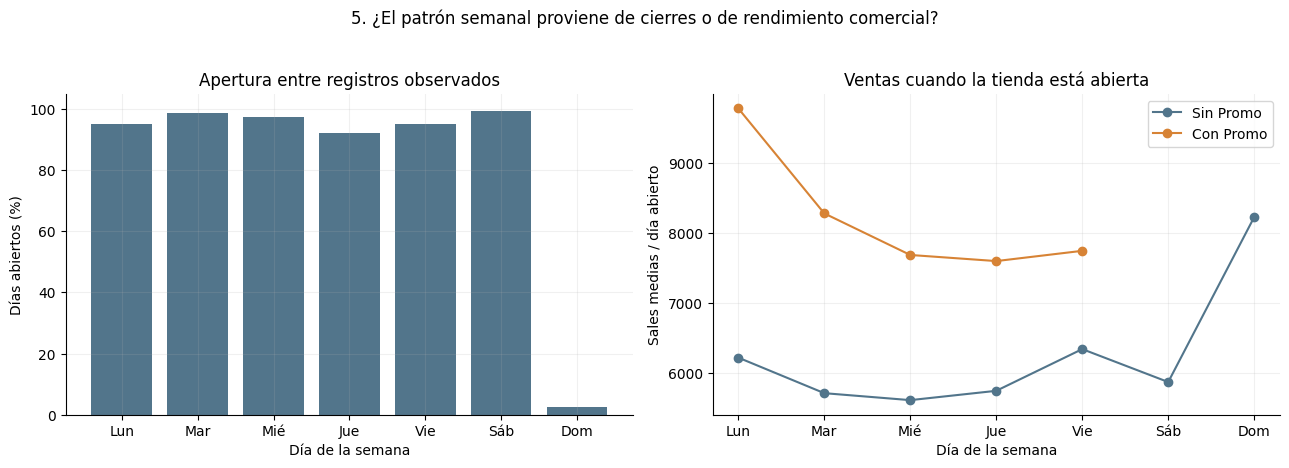

In [7]:
calendar_tables = {}
for attr in ['DayOfWeek', 'StateHoliday', 'SchoolHoliday']:
    available = eda.groupby(attr, observed=True).agg(observados=('Open', 'size'), apertura_pct=('Open', lambda s: s.mean() * 100))
    opened = summaries(open_days, attr)
    calendar_tables[attr] = available.join(opened, validate='one_to_one')
    print('Calendario:', attr)
    display(calendar_tables[attr])
weekday_promo_means = open_days.groupby(['DayOfWeek', 'Promo'], observed=True)['Sales'].mean().unstack('Promo')
weekday_promo_counts = pd.crosstab(open_days['DayOfWeek'], open_days['Promo'])
print('Soporte por día y Promo; los ceros son conteos, no imputaciones:')
display(weekday_promo_counts)
display(weekday_promo_means)
print('Composición de los días abiertos en domingo:')
sunday_types = summaries(open_days.loc[open_days['DayOfWeek'].eq(7)], 'StoreType')
sunday_types['participacion_dias_dominicales_pct'] = sunday_types['tienda_dias'] / sunday_types['tienda_dias'].sum() * 100
display(sunday_types)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(DOW, calendar_tables['DayOfWeek']['apertura_pct'], color=COLORS[0])
axes[0].set(title='Apertura entre registros observados', ylabel='Días abiertos (%)', xlabel='Día de la semana', ylim=(0, 105))
for p, label, color in [(0, 'Sin Promo', COLORS[0]), (1, 'Con Promo', COLORS[1])]:
    axes[1].plot(range(1, 8), weekday_promo_means[p].reindex(range(1, 8)), marker='o', label=label, color=color)
axes[1].set(xticks=range(1, 8), xticklabels=DOW, title='Ventas cuando la tienda está abierta', ylabel='Sales medias / día abierto', xlabel='Día de la semana')
axes[1].legend()
fig.suptitle('5. ¿El patrón semanal proviene de cierres o de rendimiento comercial?', y=1.03)
finish_figure(fig, 5)

**EVIDENCIA.** En domingo abre el 2,48 % de los registros observados:
3.593 días abiertos. Sus ventas medias condicionadas a apertura son
8.224,72, frente a 8.216,07 en lunes. No hay observaciones con
Promo = 1 en sábado o domingo; los puntos ausentes del gráfico expresan falta de
soporte, no ventas cero.
StoreType b aporta 61,68 % de esos días dominicales abiertos, aunque
solo representa 17 de las 1.115 tiendas de la red.

**INTERPRETACIÓN.** Una media baja calculada sobre todos los domingos describiría
principalmente cierres. Las tiendas que sí abren pueden ser un grupo especial;
no se generaliza su rendimiento a toda la red. Comparar dentro de cada día aporta
contexto al contraste de Promo, sin eliminar la selección de tiendas o fechas.

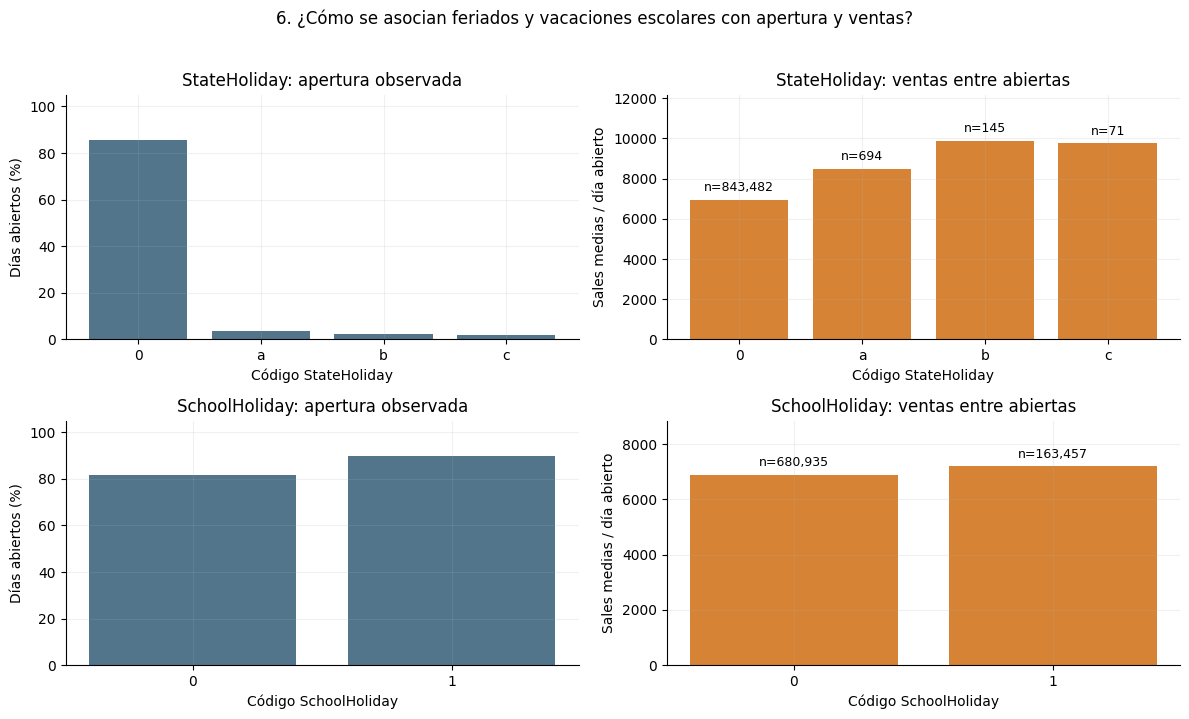

Sensibilidad por Promo en días abiertos (no es ajuste causal):


tienda_dias  tiendas   Sales_media  Sales_mediana  Customers_media  Customers_mediana  Sales_per_customer_media  Sales_per_customer_ponderada  \
StateHoliday Promo                                                                                                                                                  
0            0         467022.0   1115.0   5926.968066         5458.0       696.114162              610.0                  8.943746                      8.514362   
             1         376460.0   1115.0   8227.010275         7649.0       843.907366              757.0                 10.181194                      9.748712   
a            0            308.0     47.0   8126.837662         5714.5      1411.256494             1042.0                  6.330800                      5.758583   
             1            386.0    146.0   8775.230570         7890.0      1173.779793              845.5                  8.499978                      7.476045   
b            0             95.0     32.0   7947.210526         6476.0      1379.968421             1064.0                  6.531851                      5.758980   
             1             50.0     17.0  13575.180000        11637.0      2270.040000             1945.5                  5.920463                      5.980150   
c            0             71.0     20.0   9743.746479         8397.0      1569.225352             1394.0                  6.269964                      6.209272   

                    filas_ratio_valido  
StateHoliday Promo                      
0            0                466989.0  
             1                376441.0  
a            0                   308.0  
             1                   386.0  
b            0                    95.0  
             1                    50.0  
c            0                    71.0

tienda_dias  tiendas  Sales_media  Sales_mediana  Customers_media  Customers_mediana  Sales_per_customer_media  Sales_per_customer_ponderada  \
SchoolHoliday Promo                                                                                                                                                 
0             0         381802.0   1115.0  5876.460707         5433.0       691.000411              606.0                  8.945901                      8.504280   
              1         299133.0   1115.0  8199.082281         7621.0       843.135970              756.0                 10.160365                      9.724508   
1             0          85694.0   1115.0  6165.307793         5571.0       722.949891              628.0                  8.919860                      8.527988   
              1          77763.0   1115.0  8340.601649         7759.0       849.429112              760.0                 10.250234                      9.819067   

                     filas_ratio_valido  
SchoolHoliday Promo                      
0             0                381777.0  
              1                299118.0  
1             0                 85686.0  
              1                 77759.0

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, attr in enumerate(['StateHoliday', 'SchoolHoliday']):
    table = calendar_tables[attr]
    labels = list(map(str, table.index))
    axes[row, 0].bar(labels, table['apertura_pct'], color=COLORS[0])
    axes[row, 0].set(title=f'{attr}: apertura observada', ylabel='Días abiertos (%)', xlabel=f'Código {attr}', ylim=(0, 105))
    bars = axes[row, 1].bar(labels, table['Sales_media'], color=COLORS[1])
    axes[row, 1].bar_label(bars, labels=[f'n={int(n):,}' for n in table['tienda_dias']], fontsize=9, padding=4)
    axes[row, 1].set(title=f'{attr}: ventas entre abiertas', ylabel='Sales medias / día abierto', xlabel=f'Código {attr}', ylim=(0, table['Sales_media'].max() * 1.23))
fig.suptitle('6. ¿Cómo se asocian feriados y vacaciones escolares con apertura y ventas?', y=1.02)
finish_figure(fig, 6)
print('Sensibilidad por Promo en días abiertos (no es ajuste causal):')
for attr in ['StateHoliday', 'SchoolHoliday']:
    display(summaries(open_days, [attr, 'Promo']))

**EVIDENCIA.** Los códigos de StateHoliday distintos de `'0'` reúnen solo **910
días abiertos**; las etiquetas a/b/c se mantienen sin recodificar. Para
SchoolHoliday = 1, la fracción abierta es 89,95 % y la venta media
condicionada es 7.200,18, frente a 81,50 % y 6.896,78
para SchoolHoliday = 0.

**INTERPRETACIÓN.** Apertura y rendimiento son dimensiones diferentes. Los pocos
días abiertos en feriados pertenecen a tiendas seleccionadas y no sustentan una
recomendación general de abrir. La comparación de vacaciones escolares mezcla
geografía, fechas y promociones; las tablas por Promo permiten inspeccionarlo,
sin atribuir un efecto a las vacaciones o al feriado.

## 8. Promo2: estado temporal y ambigüedad explícita

**Pregunta:** ¿cómo difieren las ventas en meses elegibles de Promo2 después de
su inicio, evitando tratar participación como actividad durante todo el histórico?

Se construye **Promo2Active exclusivamente en `eda`**. Es un indicador analítico
de elegibilidad bajo la regla pedida, no evidencia de ejecución diaria de una campaña:

1. Promo2 = 0 → 0: los campos de detalle ausentes son «no aplica», no se imputan.
2. Para participantes, se interpreta año/semana con la convención **ISO, lunes a
   domingo**, usando `date.fromisocalendar`. Es una convención analítica declarada;
   no se confirmó la convención del proveedor ni se dispone de un día exacto de
   inicio en el CSV. Los resultados de esta sección quedan condicionados a ISO;
   no se presentan como un calendario comercial certificado.
3. Una fecha anterior a esa semana o un mes fuera de PromoInterval → 0, cuando
   los metadatos permiten decidir. Se reconoce `Sept` como septiembre solo al
   interpretar el intervalo auxiliar; no se cambia la etiqueta original.
4. Después de la semana inicial, si el mes figura en PromoInterval → 1.
5. **Durante la semana inicial**, si el mes es elegible, el estado queda **NA**:
   no se inventa si el alta ocurrió el lunes u otro día. Metadatos faltantes,
   semanas inválidas o tokens desconocidos también producirían NA, sin imputación.

Por tanto, todo 1 exige participación, fecha posterior o igual al inicio posible y
mes elegible. Los NA se cuantifican y permanecen en la población; solo se omiten
del contraste binario que no puede clasificarlos. La convención ISO y la regla por
mes no prueban el día exacto de arranque ni la duración real de cada campaña.
Referencia técnica: [Python 3.13 — calendario ISO y fromisocalendar](https://docs.python.org/3.13/library/datetime.html#datetime.date.fromisocalendar).

Problemas de metadatos de participantes: 0


,Store,problema


,todas_las_observaciones
Promo2Active,
0,865157
1,151341
<NA>,711


,dias_abiertos
Promo2Active,
0,718012
1,125825
<NA>,555


Contraste global: mezcla no participantes, preinicio y fuera de ciclo en el grupo 0


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Promo2Active,,,,,,,,,
0,718012.0,1115.0,7040.926067,6433.0,778.715524,689.0,9.403565,9.041718,717971.0
1,125825.0,571.0,6469.800572,6028.0,671.791536,605.0,10.006170,9.630667,125814.0


,tienda_dias,tiendas,Sales_media,Sales_mediana,Customers_media,Customers_mediana,Sales_per_customer_media,Sales_per_customer_ponderada,filas_ratio_valido
Promo2Active,,,,,,,,,
0,237003.0,571.0,6586.603997,6081.0,680.315169,610.0,10.039782,9.681695,236990.0
1,125825.0,571.0,6469.800572,6028.0,671.791536,605.0,10.006170,9.630667,125814.0


tienda_dias  tiendas  Sales_media  Sales_mediana  Customers_media  Customers_mediana  Sales_per_customer_media  Sales_per_customer_ponderada  \
Promo2Active Promo                                                                                                                                                 
0            0         131424.0    571.0  5524.709117         5174.0       616.350864              550.0                  9.393511                      8.963578   
             1         105579.0    571.0  7908.443308         7405.0       759.937488              688.0                 10.844191                     10.406702   
1            0          68943.0    571.0  5419.762354         5108.0       608.463238              545.0                  9.348639                      8.907296   
             1          56882.0    571.0  7742.484107         7318.0       748.547678              678.0                 10.803122                     10.343341   

                    filas_ratio_valido  
Promo2Active Promo                      
0            0                131412.0  
             1                105578.0  
1            0                 68937.0  
             1                 56877.0

Mediana del contraste dentro de tienda, participantes con ambos estados (%): -2.5270626699558707
Tiendas con ambos estados: 571


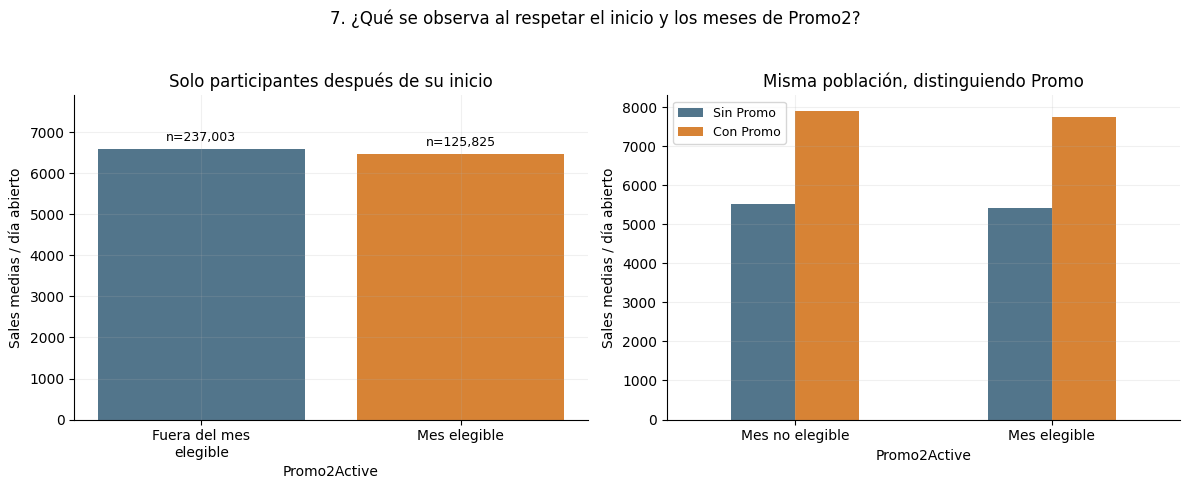

In [9]:
promo2_fields = ['Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']
promo2_stores = clean.groupby('Store', observed=True)[promo2_fields].first()
month_tokens = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
                'Jul': 7, 'Aug': 8, 'Sep': 9, 'Sept': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
start_by_store, months_by_store, promo2_issues = {}, {}, []
for store_id, row in promo2_stores.iterrows():
    if row['Promo2'] == 0:
        continue
    try:
        if pd.isna(row['Promo2SinceYear']) or pd.isna(row['Promo2SinceWeek']) or pd.isna(row['PromoInterval']):
            raise ValueError('Metadatos de participante incompletos')
        year, week = row['Promo2SinceYear'], row['Promo2SinceWeek']
        if year % 1 or week % 1:
            raise ValueError('Año o semana no enteros')
        start_by_store[store_id] = pd.Timestamp(date.fromisocalendar(int(year), int(week), 1))
        months_by_store[store_id] = {month_tokens[token] for token in row['PromoInterval'].split(',')}
    except (ValueError, KeyError, TypeError) as exc:
        start_by_store.pop(store_id, None)
        months_by_store.pop(store_id, None)
        promo2_issues.append({'Store': store_id, 'problema': str(exc)})

promo2_start = pd.to_datetime(eda['Store'].map(start_by_store))
promo2_metadata_ok = eda['Store'].isin(months_by_store)
promo2_month_ok = pd.Series(False, index=eda.index)
for interval in promo2_stores.loc[promo2_stores['Promo2'].eq(1), 'PromoInterval'].unique():
    if pd.isna(interval):
        continue
    tokens = interval.split(',')
    if not all(token in month_tokens for token in tokens):
        continue
    selected = eda['PromoInterval'].eq(interval)
    promo2_month_ok.loc[selected] = eda.loc[selected, 'Date'].dt.month.isin({month_tokens[t] for t in tokens})

eda['Promo2Active'] = pd.Series(pd.NA, index=eda.index, dtype='Int8')
eda.loc[eda['Promo2'].eq(0), 'Promo2Active'] = 0
known_participant = eda['Promo2'].eq(1) & promo2_metadata_ok & promo2_start.notna()
eda.loc[known_participant, 'Promo2Active'] = (
    eda.loc[known_participant, 'Date'].ge(promo2_start.loc[known_participant])
    & promo2_month_ok.loc[known_participant]).astype('Int8')
start_week_ambiguous = known_participant & promo2_month_ok & eda['Date'].ge(promo2_start) & eda['Date'].lt(promo2_start + pd.Timedelta(days=7))
eda.loc[start_week_ambiguous, 'Promo2Active'] = pd.NA
assert eda.loc[eda['Promo2'].eq(0), 'Promo2Active'].eq(0).all()
active = eda['Promo2Active'].eq(1) & eda['Promo2Active'].notna()
assert (eda.loc[active, 'Promo2'].eq(1)).all()
assert promo2_month_ok.loc[active].all()
assert eda.loc[active, 'Date'].ge(promo2_start.loc[active] + pd.Timedelta(days=7)).all()
print('Problemas de metadatos de participantes:', len(promo2_issues))
display(pd.DataFrame(promo2_issues, columns=['Store', 'problema']))
display(eda['Promo2Active'].value_counts(dropna=False).rename('todas_las_observaciones').to_frame())

promo2_open = eda.loc[eda['Open'].eq(1)].copy()
display(promo2_open['Promo2Active'].value_counts(dropna=False).rename('dias_abiertos').to_frame())
promo2_global = summaries(promo2_open.loc[promo2_open['Promo2Active'].notna()], 'Promo2Active')
print('Contraste global: mezcla no participantes, preinicio y fuera de ciclo en el grupo 0')
display(promo2_global)

# Comparación principal más acotada: participantes, desde la semana posterior al inicio.
promo2_eligible = promo2_open.loc[
    promo2_open['Promo2'].eq(1)
    & promo2_open['Date'].ge(promo2_start.loc[promo2_open.index] + pd.Timedelta(days=7))
    & promo2_open['Promo2Active'].notna()].copy()
promo2_main = summaries(promo2_eligible, 'Promo2Active')
promo2_cross = summaries(promo2_eligible, ['Promo2Active', 'Promo'])
display(promo2_main)
display(promo2_cross)
promo2_pair = promo2_eligible.groupby(['Store', 'Promo2Active'], observed=True)['Sales'].mean().unstack('Promo2Active')
promo2_pair = promo2_pair.loc[promo2_pair[[0, 1]].notna().all(axis=1) & promo2_pair[0].gt(0)].copy()
promo2_pair['contraste_pct'] = (promo2_pair[1] / promo2_pair[0] - 1) * 100
print('Mediana del contraste dentro de tienda, participantes con ambos estados (%):', promo2_pair['contraste_pct'].median())
print('Tiendas con ambos estados:', len(promo2_pair))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
bars = axes[0].bar(['Fuera del mes\nelegible', 'Mes elegible'], promo2_main.loc[[0, 1], 'Sales_media'], color=COLORS)
axes[0].bar_label(bars, labels=[f'n={int(n):,}' for n in promo2_main.loc[[0, 1], 'tienda_dias']], padding=4, fontsize=9)
axes[0].set(title='Solo participantes después de su inicio', ylabel='Sales medias / día abierto', xlabel='Promo2Active', ylim=(0, promo2_main['Sales_media'].max() * 1.2))
promo2_cross['Sales_media'].unstack('Promo').rename(index={0: 'Mes no elegible', 1: 'Mes elegible'}, columns={0: 'Sin Promo', 1: 'Con Promo'}).plot.bar(ax=axes[1], rot=0, color=COLORS)
axes[1].set(title='Misma población, distinguiendo Promo', ylabel='Sales medias / día abierto', xlabel='Promo2Active')
axes[1].legend(fontsize=9)
fig.suptitle('7. ¿Qué se observa al respetar el inicio y los meses de Promo2?', y=1.03)
finish_figure(fig, 7)

**EVIDENCIA.** Hay 711 estados temporales indeterminados,
555 en días abiertos, por la semana inicial elegible; se
detectaron 0 tiendas con metadatos no interpretables. Entre
participantes después de esa semana, la media es 6.469,80 en meses
elegibles y 6.586,60 fuera de ellos: diferencia relativa observada
-1,77 %. La mediana dentro de tienda es -2,53 % en
571 tiendas con ambos estados.

**INTERPRETACIÓN.** La comparación evita tratar a los participantes como activos
antes de su inicio y evita usar no participantes como control principal. Aun así,
se comparan meses, años y estados de Promo distintos; el panel por Promo no controla
toda esa composición. Un contraste negativo o débil no demostraría que Promo2
perjudica las ventas. La variable representa la elegibilidad temporal definida,
con la incertidumbre inicial conservada, y no se escribe en el clean.

## 9. ¿Qué distingue niveles altos sin fijar un target?

**Pregunta:** ¿el volumen de clientes y la escala habitual de cada tienda ayudan a
entender las ventas elevadas? Se usan relaciones continuas, medianas y percentiles
descriptivos, sin etiquetar días de «ventas altas» ni elegir un umbral de clasificación.

,Sales_mediana,Sales_p90,Sales_max
count,1115.000000,1115.000000,1115.000000
mean,6674.630942,9439.454081,15368.395516
std,2314.513962,3107.657773,5357.464254
min,2293.000000,3796.400000,5759.000000
10%,4337.300000,6124.080000,9523.000000
25%,5106.250000,7313.500000,11700.000000
50%,6332.000000,9034.600000,14531.000000
75%,7622.750000,10837.350000,17944.000000
90%,9307.800000,13193.020000,22038.400000
max,21872.000000,28210.400000,41551.000000


Los 10 días con mayor Sales observado, con su contexto:


,Store,Date,Sales,Customers,SalesPerCustomer,Promo,DayOfWeek,StateHoliday,StoreType,Assortment
44393,909,2015-06-22,41551,1721,24.143521,0,1,0,a,c
132946,262,2015-04-03,38722,5132,7.545207,1,5,b,b,a
101726,262,2015-05-01,38484,5458,7.050934,1,5,a,b,a
87231,262,2015-05-14,38367,5192,7.389638,0,4,a,b,a
424086,57,2014-06-16,38037,1970,19.308122,1,1,0,d,c
627776,817,2013-12-16,38025,4381,8.679525,1,1,0,a,a
627220,261,2013-12-16,37646,1964,19.168024,1,1,0,d,c
444361,262,2014-05-29,37403,5297,7.061167,0,4,a,b,a
620531,262,2013-12-22,37376,4916,7.602929,0,7,0,b,a
245945,262,2014-12-21,37122,4962,7.481258,0,7,0,b,a


Correlación lineal descriptiva Sales–Customers: 0.8235967321975237


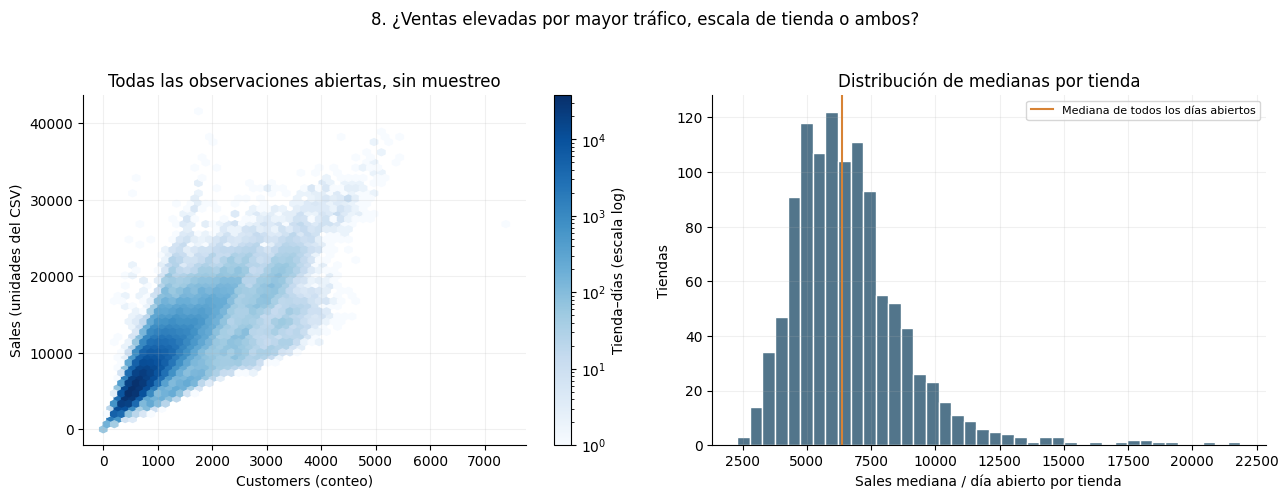

In [10]:
sales_customers_corr = open_days[['Sales', 'Customers']].corr().loc['Sales', 'Customers']
store_levels = open_days.groupby('Store', observed=True).agg(
    observaciones=('Sales', 'size'), Sales_mediana=('Sales', 'median'),
    Sales_p90=('Sales', lambda s: s.quantile(.9)), Sales_max=('Sales', 'max'),
    Customers_media=('Customers', 'mean'))
display(store_levels[['Sales_mediana', 'Sales_p90', 'Sales_max']].describe(percentiles=[.1, .25, .5, .75, .9]))
print('Los 10 días con mayor Sales observado, con su contexto:')
display(open_days.nlargest(10, 'Sales')[['Store', 'Date', 'Sales', 'Customers', 'SalesPerCustomer',
                                       'Promo', 'DayOfWeek', 'StateHoliday', 'StoreType', 'Assortment']])
print('Correlación lineal descriptiva Sales–Customers:', sales_customers_corr)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hexes = axes[0].hexbin(open_days['Customers'], open_days['Sales'], gridsize=55,
                       mincnt=1, bins='log', cmap='Blues')
assert int(hexes.get_array().sum()) == len(open_days)
fig.colorbar(hexes, ax=axes[0], label='Tienda–días (escala log)')
axes[0].set(title='Todas las observaciones abiertas, sin muestreo', xlabel='Customers (conteo)', ylabel=SALES_UNIT)
axes[1].hist(store_levels['Sales_mediana'], bins=40, color=COLORS[0], edgecolor='white')
axes[1].axvline(open_days['Sales'].median(), color=COLORS[1], label='Mediana de todos los días abiertos')
axes[1].set(title='Distribución de medianas por tienda', xlabel='Sales mediana / día abierto por tienda', ylabel='Tiendas')
axes[1].legend(fontsize=8)
fig.suptitle('8. ¿Ventas elevadas por mayor tráfico, escala de tienda o ambos?', y=1.03)
finish_figure(fig, 8)

**EVIDENCIA.** La correlación lineal Sales–Customers en días abiertos es
0,824. Las medianas de ventas por tienda van de
2.293,00 a 21.872,00. El máximo diario sigue siendo
Store 909, 2015-06-22, Sales = 41.551 con Promo = 0; otros extremos aparecen con
Promo y en tiendas de mayor volumen habitual.

**INTERPRETACIÓN.** Tráfico y tamaño comercial aportan contexto, sin explicar por
sí solos cada extremo. La escala entre tiendas advierte que un umbral global
podría describir sobre todo tiendas grandes; deberá investigarse al definir el
objetivo futuro. Customers y Sales / Customers se conocen al observar la venta:
son útiles para este EDA, **no features válidas para anticiparla**. La correlación
no establece causalidad y los extremos se mantienen.

## Hallazgos principales

1. **EVIDENCIA:** 5.873.180.623 Sales registradas; media abierta 6.955,51 y
   mediana 6.369,00, sobre 844.392 días abiertos. **INTERPRETACIÓN:**
   distinguir volumen de rendimiento por exposición evita confundir cierre con desempeño.
2. **EVIDENCIA:** Promo se asocia con 38,77 % de diferencia de media;
   8.228,28 frente a 5.929,41, con clientes medios 844,43
   frente a 696,86. **INTERPRETACIÓN:** tráfico y valor por cliente
   acompañan el contraste; no se ha estimado un efecto causal.
3. **EVIDENCIA:** mediana del uplift por tienda 40,56 %, positivo
   en 99,91 % de 1.115 tiendas elegibles.
   **INTERPRETACIÓN:** el patrón puede ser amplio sin ser homogéneo ni un retorno causal.
4. **EVIDENCIA:** por StoreType, los contrastes Promo van de 18,20 a
   42,96 %; tipo b tiene solo 17 tiendas. **INTERPRETACIÓN:** conviene
   segmentar; la composición y el soporte importan para comparar formatos.
5. **EVIDENCIA:** apertura dominical 2,48 %; rendimiento abierto
   8.224,72. El contraste de Promo lunes–viernes es 38,80 %.
   **INTERPRETACIÓN:** calendario y selección de tiendas dificultan leer un promedio
   global como «efecto de la promoción».
6. **EVIDENCIA:** el pico mensual de media abierta es 2013-12
   (8.613,46); 2014-07 a 2014-12 tiene 935 tiendas observadas por mes.
   **INTERPRETACIÓN:** las series requieren indicadores de exposición y cobertura;
   no se concluye tendencia o estacionalidad causal con este histórico limitado.
7. **EVIDENCIA:** Promo2Active, en participantes posteriores al inicio, tiene medias
   6.469,80 / 6.586,60 según mes elegible/no elegible;
   555 abiertos quedan temporalmente indeterminados.
   **INTERPRETACIÓN:** participación no equivale a actividad; el contraste temporal
   conserva selección y estacionalidad y no identifica impacto causal de Promo2.
8. **EVIDENCIA:** medianas por tienda entre 2.293,00 y
   21.872,00, y correlación contemporánea Sales–Customers
   0,824. **INTERPRETACIÓN:** anticipar niveles elevados exigirá
   distinguir escala de tienda y contexto diario, sin usar los clientes observados
   o el cociente derivado como predictores de la venta de ese día.

## Implicancias para Machine Learning

- **Candidatas a investigar, si están disponibles antes de la venta:** Store,
  StoreType, Assortment, Promo planificada, calendario (día, mes, feriados escolares
  y estatales) y apertura conocida. Las asociaciones descriptivas no equivalen a
  importancia predictiva validada. El código Store es un identificador, no una escala.
- **Promo2Active:** candidata solo como regla temporal documentada y con metadatos
  disponibles en el momento de predicción. Resolver convención de semana, incertidumbre
  inicial y sentido de los meses antes de reutilizarla; no se entrenó ni exportó.
- **Sales, Customers y Sales / Customers:** excluidas como features contemporáneas.
  Las estadísticas futuras o calculadas sobre todo el histórico tampoco deben
  trasladarse a un pipeline. Cualquier estadística aprendida deberá usar solo
  entrenamiento y respetar la cronología.
- **Target pendiente:** la heterogeneidad de medianas aconseja evaluar una
  definición que no capture únicamente tamaño de tienda. No se selecciona un
  percentil, umbral ni etiqueta definitivos en esta fase.
- La evaluación temporal, imputación de competencia u otros campos, encoding,
  scaling y modelos quedan para sus notebooks. Los 54 registros conocidos no se
  descartan y el clean mantiene sus faltantes y valores observados.

## Evidencia candidata para dashboard y case study

**Cinco KPIs, con filtro Open = 1 salvo el primero:**

| KPI | Valor observado | Definición de exposición |
|---|---:|---|
| Sales totales registradas | 5.873.180.623 | Todas las filas disponibles; mostrar cobertura y período. |
| Sales medias por día abierto | 6.955,51 | Tienda–días Open = 1, incluidos ceros conocidos. |
| Clientes medios por día abierto | 762,73 | Mismo denominador abierto. |
| Abiertos con Promo | 44,64 % | Filas abiertas con Promo / filas abiertas. |
| Uplift global observado de Promo | 38,77 % | Cociente de medias abiertas, descriptivo; mostrar tamaños y calendario. |

**Cuatro visualizaciones reutilizables conceptualmente:**

- **Figura 1:** total mensual y media por día abierto, con cobertura/cohorte visibles.
- **Figura 2:** ventas, clientes y ventas por cliente con/sin Promo, con filtro de apertura.
- **Figura 3:** distribución del contraste por tienda y relación con el nivel base.
- **Figura 6:** apertura y rendimiento abierto por feriados/vacaciones escolares,
  incluyendo el soporte de cada grupo.

**Tres mensajes comerciales candidatos:**

- Promo coincide con una mayor media de ventas y mayor tráfico en el agregado,
  con heterogeneidad por tienda; priorizar preguntas de segmentación, sin atribuir causalidad.
- Volumen mensual y domingos necesitan contexto de cobertura y apertura; una caída
  del total registrado no demuestra deterioro de productividad.
- Promo2 requiere fecha de inicio y mes elegible; su contraste debe comunicarse
  con incertidumbre temporal y sin usar participantes/no participantes como experimento.

Estas piezas quedan seleccionadas para reutilización posterior. No se modifican
el dashboard, el memo, el README ni otros entregables durante esta fase.

In [11]:
assert figures_created == list(range(1, 9)), 'Se esperan exactamente ocho figuras'
assert file_sha256(CLEAN_PATH) == clean_sha_before
assert hashlib.sha256(pd.util.hash_pandas_object(clean, index=True).values.tobytes()).hexdigest() == clean_frame_before
assert (tuple(clean.columns), tuple(map(str, clean.dtypes))) == clean_schema_before
assert protected_hashes == {str(p.relative_to(ROOT)): file_sha256(p) for p in protected_paths}
assert 'Promo2Active' not in clean.columns
assert len(open_days) == int(clean['Open'].eq(1).sum())
assert open_days['Sales'].eq(0).sum() == 54
print('Validación: clean intacto en disco y memoria; Fase 1, otros notebooks y documentos sin cambios.')
print('Ocho figuras generadas. Sin target, dataset ML, split, imputación de ML ni entrenamiento.')
print('Fin de Fase 2: EDA completado.')

Validación: clean intacto en disco y memoria; Fase 1, otros notebooks y documentos sin cambios.
Ocho figuras generadas. Sin target, dataset ML, split, imputación de ML ni entrenamiento.
Fin de Fase 2: EDA completado.
